# Spatial Discretization: Step, Diamond and Step Characteristic

The discrete ordinates sweep marches across each cell from the incoming edge
to the outgoing edge. A spatial discretization closes that step by relating
the cell-average angular flux to the two edge fluxes:

$$
\psi_{i} = \alpha_\text{in}\,\psi_\text{in} + \alpha_\text{out}\,\psi_\text{out},
\qquad \alpha_\text{in} + \alpha_\text{out} = 1 .
$$

ANTS supports three choices, set with `GeometryData(space_disc=...)`:

| `SpatialDiscretization` | $\alpha_\text{in}$ | $\alpha_\text{out}$ |
|---|---|---|
| `STEP` | 0 | 1 |
| `DIAMOND` (default) | 1/2 | 1/2 |
| `STEP_CHARACTERISTIC` | $\tfrac{1}{2}(1 - c)$ | $\tfrac{1}{2}(1 + c)$ |

For step characteristic, $c = \coth(\tau/2) - 2/\tau$ with optical thickness
$\tau = \sigma_t \Delta x / |\mu|$. It moves from diamond ($c \to 0$) in
optically thin cells toward step ($c \to 1$) in thick ones.

This notebook compares them on two problems: a smooth manufactured solution
that measures order of accuracy, and Reed's problem on a coarse mesh, where
the differences in robustness show up. It also plots the scattering reaction
rate, which is what a user would typically tally from the flux.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import ants
from ants.datatypes import (
    GeometryData,
    MaterialData,
    SolverData,
    SourceData,
    SpatialDiscretization,
)
from ants.fixed1d import fixed_source
from ants.utils import manufactured_1d as mms

# Plot colors: one per method, plus a neutral dashed reference
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
REFERENCE = dict(color="#52514e", ls="--", lw=2)


def tidy(ax):
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

## Order of accuracy

The manufactured solution $\psi(x, \mu) = \tfrac{1}{2} + \tfrac{1}{4} x^2 e^{\mu}$
on $x \in [0, 1]$ with $\sigma_t = 1$ and $\sigma_s = 0.9$ is smooth, so the
error should fall at the theoretical rate as the mesh is refined. ANTS
provides the matching external and boundary sources in
`ants.external1d.manufactured_ss_03` and `ants.boundary1d.manufactured_ss_03`.

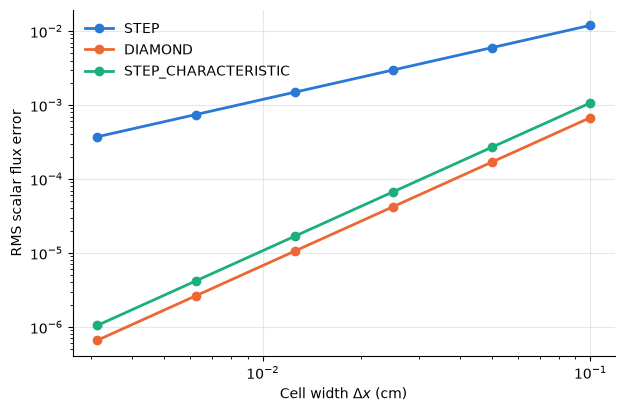

STEP                 observed order: [1. 1. 1. 1. 1.]
DIAMOND              observed order: [2. 2. 2. 2. 2.]
STEP_CHARACTERISTIC  observed order: [2. 2. 2. 2. 2.]


In [2]:
quadrature = ants.angular_x(8)
mms_materials = MaterialData(
    total=np.array([[1.0]]),
    scatter=np.array([[[0.9]]]),
    fission=np.array([[[0.0]]]),
)


def solve_mms(cells, space_disc):
    edges_x = np.linspace(0.0, 1.0, cells + 1)
    centers_x = 0.5 * (edges_x[1:] + edges_x[:-1])
    sources = SourceData(
        external=ants.external1d.manufactured_ss_03(centers_x, quadrature.angle_x),
        boundary_x=ants.boundary1d.manufactured_ss_03(quadrature.angle_x),
    )
    geometry = GeometryData(
        medium_map=np.zeros(cells, dtype=np.int32),
        delta_x=np.diff(edges_x),
        space_disc=space_disc,
    )
    flux = fixed_source(mms_materials, sources, geometry, quadrature, SolverData())
    exact = mms.solution_ss_03(centers_x, quadrature.angle_x) @ quadrature.angle_w
    return np.sqrt(np.mean((flux[:, 0] - exact) ** 2))


mesh = np.array([10, 20, 40, 80, 160, 320])
errors = {
    disc: np.array([solve_mms(cells, disc) for cells in mesh])
    for disc in SpatialDiscretization
}

fig, ax = plt.subplots(figsize=(7, 4.5))
for color, (disc, error) in zip(COLORS, errors.items()):
    ax.loglog(1.0 / mesh, error, color=color, lw=2, marker="o", ms=6, label=disc.name)
ax.set_xlabel("Cell width $\\Delta x$ (cm)")
ax.set_ylabel("RMS scalar flux error")
ax.legend(frameon=False)
tidy(ax)
plt.show()

for disc, error in errors.items():
    order = np.log2(error[:-1] / error[1:])
    print(f"{disc.name:20s} observed order: {np.round(order, 2)}")

Step is first order, while diamond and step characteristic are both second
order. Diamond has the smallest error constant on this smooth problem.

## Reed's problem on a coarse mesh

Reed's problem is a 16 cm slab with vacuum boundaries and five regions,
symmetric about $x = 8$ cm:

| Region | Location (cm) | $\sigma_t$ | $\sigma_s$ | Source |
|---|---|---|---|---|
| Scatterer | 0-4, 12-16 | 1 | 0.9 | 1 in 2-4 and 12-14, otherwise 0 |
| Void | 4-5, 11-12 | 0 | 0 | 0 |
| Absorber | 5-6, 10-11 | 5 | 0 | 0 |
| Source | 6-10 | 50 | 0 | 50 |

The thin void, the thick absorber and the very thick source region make it a
standard stress test for transport discretizations.

The reference solution uses diamond difference on a 3200-cell mesh. The
coarse runs use 64 cells (0.25 cm), which puts the source region at an
optical thickness of 12.5 per cell along the slab.

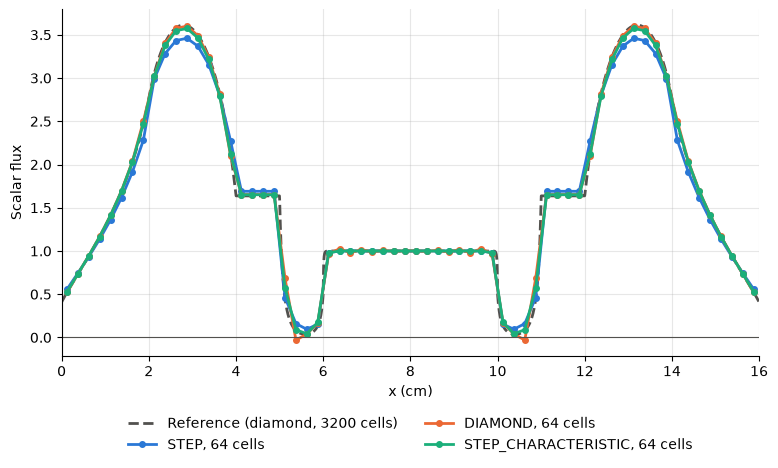

STEP                 minimum flux  0.0941 at x = 5.625 cm, maximum error 0.192
DIAMOND              minimum flux -0.0302 at x = 10.625 cm, maximum error 0.238
STEP_CHARACTERISTIC  minimum flux  0.0421 at x = 10.375 cm, maximum error 0.130


In [3]:
layers = [
    [0, "scatterer", "0-4, 12-16"],
    [1, "void", "4-5, 11-12"],
    [2, "absorber", "5-6, 10-11"],
    [3, "source", "6-10"],
]
reed_materials = MaterialData(
    total=np.array([[1.0], [0.0], [5.0], [50.0]]),
    scatter=np.array([[[0.9]], [[0.0]], [[0.0]], [[0.0]]]),
    fission=np.zeros((4, 1, 1)),
    velocity=np.ones(1),
)
quadrature = ants.angular_x(8)


def solve_reed(cells, space_disc):
    edges_x = np.linspace(0.0, 16.0, cells + 1)
    medium_map = ants.spatial1d(layers, edges_x)
    sources = SourceData(
        external=ants.external1d.reeds(edges_x, [0, 0]),
        boundary_x=np.zeros((2, 1, 1)),
    )
    geometry = GeometryData(
        medium_map=medium_map,
        delta_x=np.diff(edges_x),
        bc_x=[0, 0],
        geometry=1,
        space_disc=space_disc,
    )
    flux = fixed_source(reed_materials, sources, geometry, quadrature, SolverData())
    centers_x = 0.5 * (edges_x[1:] + edges_x[:-1])
    return centers_x, medium_map, flux


coarse = 64
x_ref, map_ref, flux_ref = solve_reed(3200, SpatialDiscretization.DIAMOND)
coarse_runs = {disc: solve_reed(coarse, disc) for disc in SpatialDiscretization}

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x_ref, flux_ref[:, 0], label="Reference (diamond, 3200 cells)", **REFERENCE)
for color, (disc, (x, _, flux)) in zip(COLORS, coarse_runs.items()):
    ax.plot(x, flux[:, 0], color=color, lw=2, marker="o", ms=4,
            label=f"{disc.name}, {coarse} cells")
ax.axhline(0.0, color="#52514e", lw=0.8)
ax.set_xlabel("x (cm)")
ax.set_ylabel("Scalar flux")
ax.set_xlim(0, 16)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
tidy(ax)
plt.show()

for disc, (x, _, flux) in coarse_runs.items():
    low = np.argmin(flux[:, 0])
    error = np.abs(flux[:, 0] - np.interp(x, x_ref, flux_ref[:, 0])).max()
    print(f"{disc.name:20s} minimum flux {flux[low, 0]: .4f} at x = {x[low]:.3f} cm, "
          f"maximum error {error:.3f}")

All three coarse solutions follow the reference, but they fail in
different ways. Diamond difference goes negative in the absorbers (the minimum
is printed above) and overshoots at the edges of the source region. Negative
flux is unphysical, and any reaction rate computed from it is negative too.
Step difference stays positive everywhere, but it is more diffusive: it
flattens the peaks in the scattering regions and smears the sharp changes at
material interfaces.

Step characteristic is close to step in the optically thick absorber and
source cells, and close to diamond in the scatterers and voids. Here it stays
positive, does not overshoot, and has the smallest maximum error of the three.
It is not guaranteed to be positive on every problem.

## Scattering reaction rate

The scattering reaction rate density is $R_s(x) = \sum_g \sigma_{s,g}(x)\,
\phi_g(x)$, where $\sigma_{s,g}$ is the total scattering cross section out of
group $g$. The helper below computes it from `MaterialData.scatter`, which is
indexed `[material, group out, group in]`.

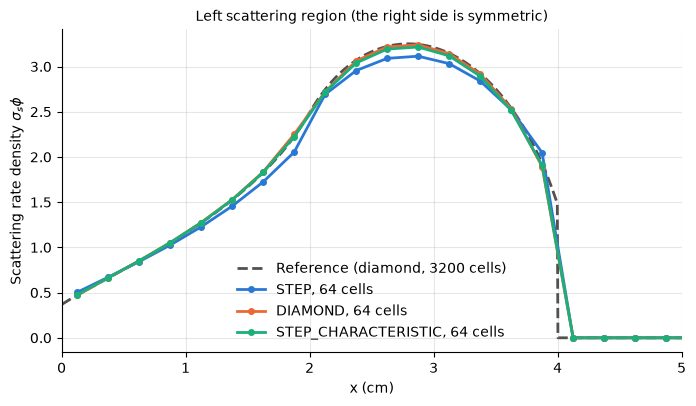

STEP                 total scattering rate 15.8957  (-2.61% vs reference 16.3223)
DIAMOND              total scattering rate 16.3218  (-0.00% vs reference 16.3223)
STEP_CHARACTERISTIC  total scattering rate 16.2441  (-0.48% vs reference 16.3223)


In [4]:
def scattering_rate(flux, scatter, medium_map):
    """Scattering reaction rate density, sigma_s * phi, in each cell.

    scatter is indexed [material, group out, group in], so summing over the
    outgoing group gives the total scattering cross section of each group.
    flux has the cell axes first and groups last.
    """
    sigma_s = scatter.sum(axis=1)  # (materials, groups)
    return np.sum(sigma_s[medium_map] * flux, axis=-1)


rate_ref = scattering_rate(flux_ref, reed_materials.scatter, map_ref)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(x_ref, rate_ref, label="Reference (diamond, 3200 cells)", **REFERENCE)
for color, (disc, (x, medium_map, flux)) in zip(COLORS, coarse_runs.items()):
    rate = scattering_rate(flux, reed_materials.scatter, medium_map)
    ax.plot(x, rate, color=color, lw=2, marker="o", ms=4,
            label=f"{disc.name}, {coarse} cells")
ax.set_xlim(0, 5)
ax.set_xlabel("x (cm)")
ax.set_ylabel("Scattering rate density $\\sigma_s \\phi$")
ax.set_title("Left scattering region (the right side is symmetric)", fontsize=10)
ax.legend(frameon=False)
tidy(ax)
plt.show()

dx_ref = 16.0 / len(x_ref)
total_ref = rate_ref.sum() * dx_ref
for disc, (x, medium_map, flux) in coarse_runs.items():
    total = scattering_rate(flux, reed_materials.scatter, medium_map).sum() * (16.0 / coarse)
    print(f"{disc.name:20s} total scattering rate {total:.4f}  "
          f"({100 * (total / total_ref - 1):+.2f}% vs reference {total_ref:.4f})")

The scattering rate follows the flux, since $\sigma_s$ is constant in
the scatterers and zero everywhere else. Step difference underpredicts the
peak and the total scattering rate. Diamond difference matches the reference
total almost exactly, and step characteristic is close behind.

On this mesh diamond difference gives the best total reaction rate, step
difference never goes negative but loses accuracy, and step characteristic is
second order like diamond while avoiding its oscillations in thick cells.